# 04 · Бэктест торговли

Можно ли заработать, если покупать лоты, которые модель считает дешёвыми? **Бэктест**
проверяет стратегию на истории: мы «проигрываем» прошлое так, будто торговали в нём, и
считаем, сколько бы заработали.

Правила простые:

1. Покупаем каждый лот, цена которого хотя бы на 10–15% ниже оценки модели.
2. Ждём 7 дней: столько на CSFloat действует запрет на передачу купленного предмета.
3. Продаём по медиане похожих продаж (тот же предмет, float в пределах ±0,01) и
   платим 2% комиссии.
4. Для контроля столько же лотов из того же пула покупаем случайно. Если модель
   действительно что-то умеет, она должна заметно обыграть случайные покупки.

Подробности и ловушки — в `experiments/07_trading_backtest/README.md`, код — в
`src/skinprice/research/trading.py`.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from skinprice import paths
from skinprice.research.labels import russian, value
from skinprice.research.plots import NEUTRAL, SERIES, apply_style

apply_style()
tables = {k: pd.DataFrame(v) for k, v in json.loads(
    (paths.EXPERIMENTS_DIR / "07_trading_backtest" / "results.json").read_text(encoding="utf-8"))["tables"].items()}

## Сначала проверим линейку: правильно ли оценивается цена перепродажи?

Если оценка перепродажи систематически завышена, бэктест покажет прибыль, которой нет.
Поэтому на всех кандидатах на покупку сравниваем оценку перепродажи с реальной ценой
лота. И медиана, и среднее отношения должны быть близки к 1. Для обычных предметов и
крафтов так и есть (0,98–0,99).

In [2]:
russian(tables["resale_estimator_bias"])

,сегмент,лотов,"есть оценка перепродажи, %",медиана прогноз/факт,среднее прогноз/факт
0,с брелоком,1552,0.9,0.9550,0.9148
1,обычный предмет,93147,56.7,0.9833,0.9889
2,крафт,19781,12.0,0.9773,0.9865


## Деньги

Окно покупок — семь дней. «Висели >10 мин» оставляет только лоты, которые человек
реально успел бы купить; остальные за минуты забирают боты. «Преимущество над
случайными» — на сколько процентных пунктов доходность выше, чем у случайных покупок из
того же пула.

Сравниваются два сигнала: модель и оценка CSFloat. Неожиданно оценка CSFloat работает не
хуже модели. Модель учится предсказывать цену именно этого лота, поэтому её сигнал
«дёшево» отчасти срабатывает там, где она сама ошибается.

In [3]:
money = tables["money"]
russian(money[["segment", "scope", "signal", "trades", "capital_usd", "profit_usd", "roi_pct", "roi_ci90",
               "random_roi_pct", "edge_pp", "avg_ticket_usd"]])

,сегмент,какие лоты,сигнал на покупку,сделок,"вложено, $","прибыль, $","доходность, %","доходность, 90%-интервал","доходность случайных покупок, %","преимущество над случайными, п.п.","средняя покупка, $"
0,обычный предмет,все лоты,"модель, скидка ≥10%",11343,24097,1421,5.90,4.77 .. 7.06,-6.40,12.3,2.12
1,обычный предмет,все лоты,"модель, скидка ≥15%",7114,10190,942,9.25,7.51 .. 10.99,-6.61,15.9,1.43
2,обычный предмет,все лоты,"оценка CSFloat, скидка ≥10%",13448,57038,1593,2.79,1.54 .. 3.85,-6.35,9.1,4.24
3,обычный предмет,все лоты,"оценка CSFloat, скидка ≥15%",8354,18036,1825,10.12,9.03 .. 11.19,-6.57,16.7,2.16
4,обычный предмет,висели >10 мин,"модель, скидка ≥10%",4347,17448,396,2.27,1.04 .. 3.49,-7.50,9.8,4.01
5,обычный предмет,висели >10 мин,"модель, скидка ≥15%",2439,6760,289,4.28,2.28 .. 6.22,-7.93,12.2,2.77
6,обычный предмет,висели >10 мин,"оценка CSFloat, скидка ≥10%",4904,37144,93,0.25,-1.47 .. 1.67,-7.52,7.8,7.57
7,обычный предмет,висели >10 мин,"оценка CSFloat, скидка ≥15%",2308,10295,634,6.15,4.75 .. 7.63,-7.32,13.5,4.46
8,крафт,все лоты,"модель, скидка ≥10%",1044,16952,-474,-2.80,-9.68 .. 2.98,-7.75,5.0,16.24
9,крафт,все лоты,"модель, скидка ≥15%",539,5747,209,3.64,0.59 .. 7.04,-7.81,11.5,10.66


## Кто забирает дешёвые лоты? Доходность в зависимости от того, сколько лот висел

Обычные предметы, сигнал модели при скидке 15%. Модель обыгрывает случайные покупки в
каждой группе, то есть у неё есть настоящее умение. Но основные деньги в лотах, которые
продаются за минуты, а их выкупают боты.

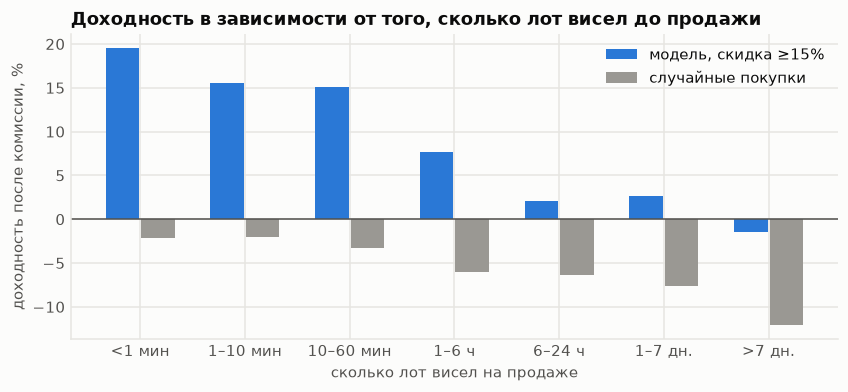

,сколько лот висел,лотов,"доля лотов, %",медиана цена/прогноз,сделок,"доходность, %","доходность случайных покупок, %","преимущество над случайными, п.п."
0,<1 мин,31518,33.8,1.031,4416,19.55,-2.12,21.7
1,1–10 мин,3592,3.9,1.020,259,15.59,-2.06,17.7
2,10–60 мин,4801,5.2,1.011,461,15.10,-3.31,18.4
3,1–6 ч,10422,11.2,1.016,521,7.62,-6.04,13.7
4,6–24 ч,14658,15.7,1.029,548,2.08,-6.40,8.5
5,1–7 дн.,19257,20.7,1.046,600,2.64,-7.63,10.3
6,>7 дн.,8899,9.6,1.088,309,-1.49,-12.09,10.6


In [4]:
tom = tables["time_on_market_clean_model15"].dropna(subset=["roi_pct"])
x = np.arange(len(tom))
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(x - 0.17, tom["roi_pct"], width=0.32, color=SERIES[0], label="модель, скидка ≥15%")
ax.bar(x + 0.17, tom["random_roi_pct"], width=0.32, color=NEUTRAL, label="случайные покупки")
ax.axhline(0, color="#52514e", linewidth=1)
ax.set_xticks(x, [value(str(v)) for v in tom["time_on_market"]])
ax.set_xlabel("сколько лот висел на продаже")
ax.set_ylabel("доходность после комиссии, %")
ax.set_title("Доходность в зависимости от того, сколько лот висел до продажи")
ax.legend(loc="upper right")
plt.show()
russian(tom)

## Насколько результат зависит от допуска по float

Если считать «похожими» предметы с float в пределах ±0,05 вместо ±0,01, в одну группу
попадают физически разные предметы, и прибыль превращается в убыток. Это одна из ловушек,
найденных в исходном исследовании.

In [5]:
russian(tables["float_tolerance_clean_access_model10"])

,допуск по float,сделок,"вложено, $","прибыль, $","доходность, %","доходность, 90%-интервал","доходность случайных покупок, %","преимущество над случайными, п.п.","прибыльных сделок, %","средняя покупка, $","прибыль в месяц, $"
0,0.01,4347,17448,396,2.27,1.04 .. 3.49,-7.50,9.8,55.9,4.01,1695
1,0.05,5335,22921,-1468,-6.40,-9.20 .. -3.85,-9.35,2.9,54.0,4.30,-6291


## Быстрая перепродажа по 25-му перцентилю похожих продаж

Если продавать не по медиане, а дешевле, чтобы продать быстрее (по 25-му перцентилю),
доходность почти исчезает.

In [6]:
russian(tables["quick_resale_p25"])

,сигнал на покупку,сделок,"вложено, $","прибыль, $","доходность, %","доходность, 90%-интервал","доходность случайных покупок, %","преимущество над случайными, п.п.","прибыльных сделок, %","средняя покупка, $","прибыль в месяц, $"
0,"модель, скидка ≥10%",11343,24097,-143,-0.59,-1.54 .. 0.43,-10.08,9.5,50.3,2.12,-612
1,"модель, скидка ≥15%",7114,10190,137,1.35,-0.38 .. 3.11,-10.11,11.5,54.0,1.43,589
